In [748]:
import pandas as pd
import numpy as np
import sklearn
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
%matplotlib inline

In [749]:
df = pd.read_csv ('data.csv')

In [750]:
# REPLACE ALL NULL VALUES WITH MEAN 

df = df.fillna(df.mean())
df = df.set_index('COUNTRY')

df.head()

,Fragile States Index,"Women, Peace, and Security Index",Poverty Rate(2010-2020),Infant Mortality,Unemployment Rate(2000-2020),Violent Crime Index Rate(2022),Suicide Rate(2022),Incarceration Rate(2022),Global Rate Depression(2022),Global Alcoholism rate(2019),Global Drug Rate(2019)
COUNTRY,,,,,,,,,,,
Afghanistan,69.2,0.373000,54.500000,44.97,11.7,6.66,4.1,77.0,3.3,0.44,0.52
Albania,35.2,0.759000,14.300000,8.76,11.7,2.29,4.3,179.0,4.8,1.79,0.49
Algeria,48.2,0.611000,5.500000,19.46,13.6,1.36,2.5,153.0,4.5,0.43,0.49
Angola,58.5,0.626000,32.300000,48.34,9.6,4.85,6.1,89.0,3.6,1.10,0.36
Antigua and Barbuda,33.8,0.713402,27.767089,5.38,8.4,11.06,0.4,216.0,5.1,5.10,0.83


In [751]:
# apply normalization technique to Global peace index
# column = 'Global Peace Index(2022)'

# df[column] = MinMaxScaler().fit_transform(np.array(df[column]).reshape(-1,1))

In [752]:
# Adjust column values

df['Fragile States Index'] = df['Fragile States Index'].apply(lambda x: x/100)
df['Infant Mortality'] = df['Infant Mortality'].apply(lambda x: x/100)
df['Women, Peace, and Security Index'] = df['Women, Peace, and Security Index'].apply(lambda x: (1-x)/2)

# /100
df['Poverty Rate(2010-2020)'] = df['Poverty Rate(2010-2020)'].apply(lambda x: x/100)
df['Unemployment Rate(2000-2020)'] = df['Unemployment Rate(2000-2020)'].apply(lambda x: x/100 - .04)
df['Suicide Rate(2022)'] = df['Suicide Rate(2022)'].apply(lambda x: x/100)
df['Violent Crime Index Rate(2022)'] = df['Violent Crime Index Rate(2022)'].apply(lambda x: x/100)

df['Incarceration Rate(2022)'] = df['Incarceration Rate(2022)'].apply(lambda x: x/10000)


df['Global Rate Depression(2022)'] = df['Global Rate Depression(2022)'].apply(lambda x: x/100)
df['Global Alcoholism rate(2019)'] = df['Global Alcoholism rate(2019)'].apply(lambda x: x/100)
df['Global Drug Rate(2019)'] = df['Global Drug Rate(2019)'].apply(lambda x: x/100)


# Inverse HDI & Freedom Index
# df['HDI(2022)'] = df['HDI(2022)'].apply(lambda x: (1-x))
# GGI effects roughly 1/2 the population
# df['GGI(2021)'] = df['GGI(2021)'].apply(lambda x: x/10)

# Lowering global peace index weight to bring into line with HDI
# df['Global Peace Index(2022)'] = df['Global Peace Index(2022)'].apply(lambda x: x/10)

# df['Divorce Rate'] = df['Divorce Rate'].apply(lambda x: x/1000)



In [753]:
df.head()

,Fragile States Index,"Women, Peace, and Security Index",Poverty Rate(2010-2020),Infant Mortality,Unemployment Rate(2000-2020),Violent Crime Index Rate(2022),Suicide Rate(2022),Incarceration Rate(2022),Global Rate Depression(2022),Global Alcoholism rate(2019),Global Drug Rate(2019)
COUNTRY,,,,,,,,,,,
Afghanistan,0.692,0.313500,0.545000,0.4497,0.077,0.0666,0.041,0.0077,0.033,0.0044,0.0052
Albania,0.352,0.120500,0.143000,0.0876,0.077,0.0229,0.043,0.0179,0.048,0.0179,0.0049
Algeria,0.482,0.194500,0.055000,0.1946,0.096,0.0136,0.025,0.0153,0.045,0.0043,0.0049
Angola,0.585,0.187000,0.323000,0.4834,0.056,0.0485,0.061,0.0089,0.036,0.0110,0.0036
Antigua and Barbuda,0.338,0.143299,0.277671,0.0538,0.044,0.1106,0.004,0.0216,0.051,0.0510,0.0083


In [754]:
df['GDM'] = df.sum(numeric_only = True, axis = 1)

# normlaize to 100
# column = 'GDM'
# df[column] = MinMaxScaler().fit_transform(np.array(df[column]).reshape(-1,1))

df_sort = df.sort_values(by=['GDM'], ascending=False)
display (df_sort)

,Fragile States Index,"Women, Peace, and Security Index",Poverty Rate(2010-2020),Infant Mortality,Unemployment Rate(2000-2020),Violent Crime Index Rate(2022),Suicide Rate(2022),Incarceration Rate(2022),Global Rate Depression(2022),Global Alcoholism rate(2019),Global Drug Rate(2019),GDM
COUNTRY,,,,,,,,,,,,
Lesotho,0.461,0.179500,0.497,0.6988,0.184000,0.435600,0.724,0.00920,0.048,0.022300,0.006200,3.265600
Somalia,1.123,0.143299,0.730,0.7272,0.091000,0.070389,0.079,0.00246,0.040,0.015741,0.007292,3.029380
Central African Republic,0.726,0.243500,0.620,0.7750,0.040611,0.201200,0.123,0.00160,0.042,0.011200,0.003400,2.787511
South Sudan,0.754,0.260500,0.764,0.6334,0.082000,0.148700,0.039,0.00500,0.044,0.013800,0.003500,2.747900
Equatorial Guinea,0.574,0.187000,0.768,0.5828,0.210000,0.070389,0.079,0.00630,0.042,0.011900,0.004300,2.535689
...,...,...,...,...,...,...,...,...,...,...,...,...
Finland,0.094,0.054500,0.122,0.0188,0.038000,0.016300,0.153,0.00500,0.056,0.024900,0.011300,0.593800
Ireland,0.136,0.071000,0.131,0.0262,0.016000,0.008900,0.096,0.00750,0.048,0.035400,0.013500,0.589500
Netherlands,0.145,0.060500,0.136,0.0358,-0.002000,0.005900,0.118,0.00600,0.047,0.018100,0.011500,0.581800


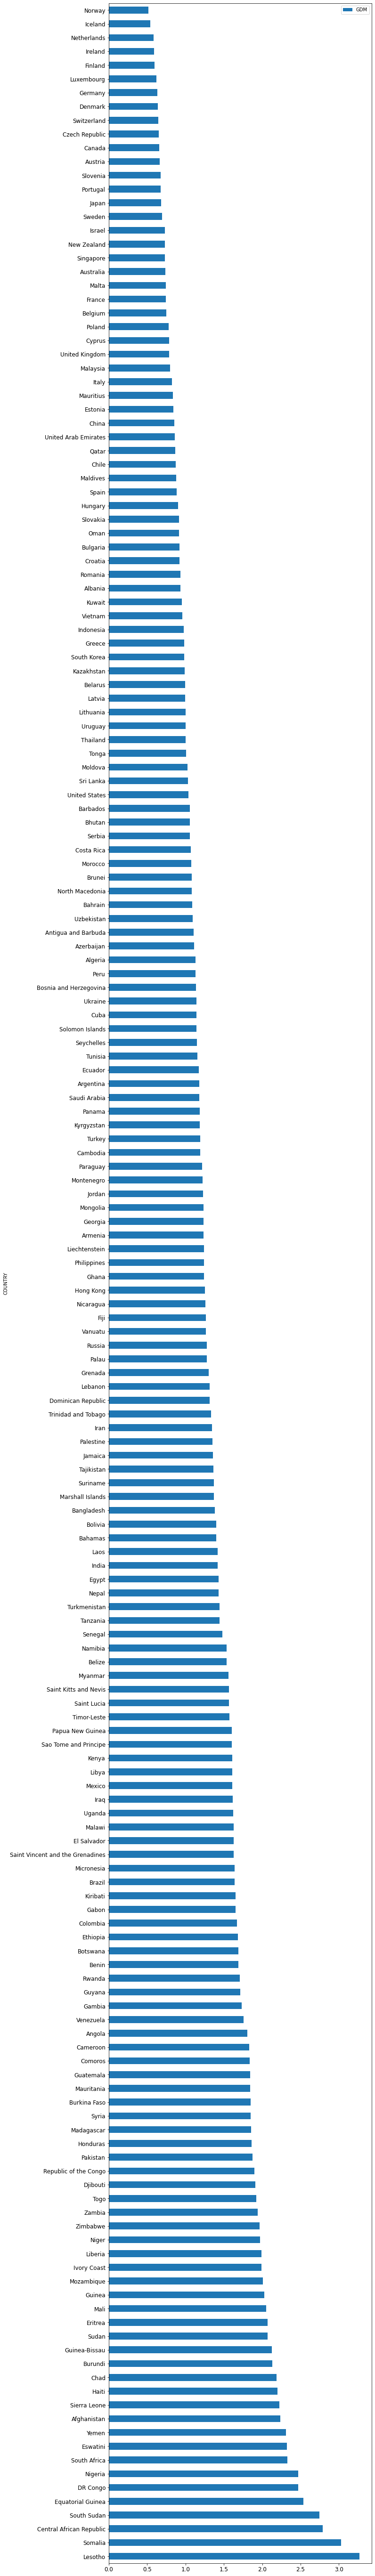

In [755]:
barh_all = df_sort.plot.barh(y='GDM', fontsize='12', figsize=(10,100))


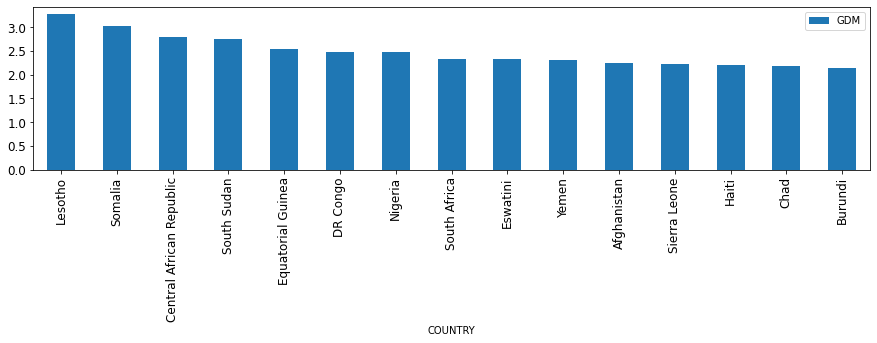

In [756]:
bottom_15 = df_sort.head(15)
barh_bottom_15 = bottom_15.plot.bar(y='GDM', fontsize='12', figsize=(15,3))

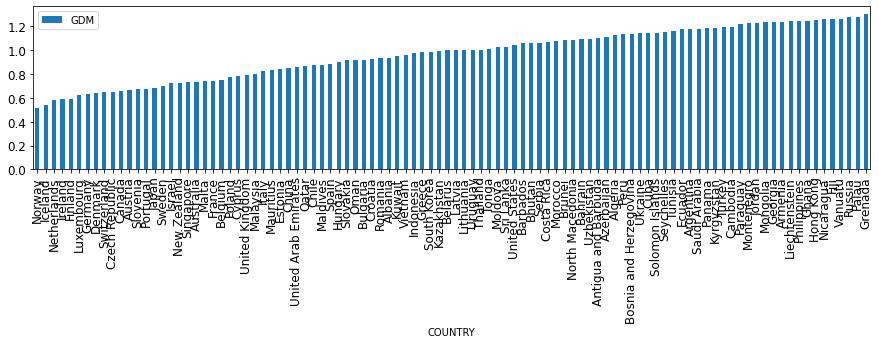

In [757]:
top_15 = df_sort.tail(100)
top_15 = top_15.sort_values(by='GDM')
barh_bottom_15 = top_15.plot.bar(y='GDM', fontsize='12', figsize=(15,3))

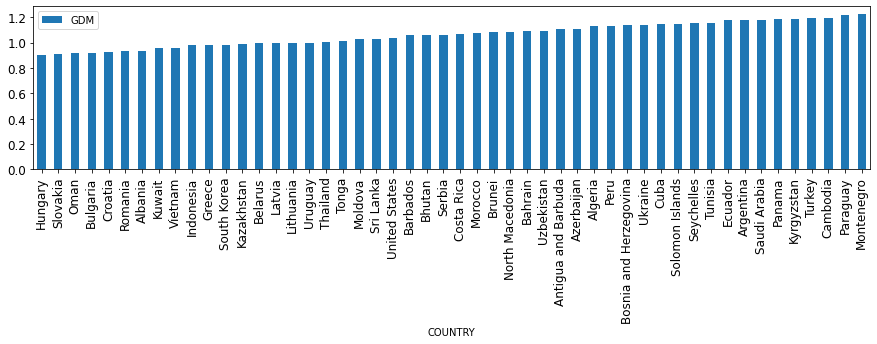

In [758]:
united_states_peers = df_sort.iloc[100:150]
united_states_peers = united_states_peers.sort_values(by='GDM')
united_states_peers = united_states_peers.plot.bar(y='GDM', fontsize='12', figsize=(15,3))

In [759]:
df_sort.shape

(186, 12)

In [760]:
df_sort.loc[['Mexico', 'Ivory Coast']]

,Fragile States Index,"Women, Peace, and Security Index",Poverty Rate(2010-2020),Infant Mortality,Unemployment Rate(2000-2020),Violent Crime Index Rate(2022),Suicide Rate(2022),Incarceration Rate(2022),Global Rate Depression(2022),Global Alcoholism rate(2019),Global Drug Rate(2019),GDM
COUNTRY,,,,,,,,,,,,
Mexico,0.493,0.1535,0.419,0.1177,0.005,0.290700,0.053,0.0169,0.042,0.013900,0.005800,1.610500
Ivory Coast,0.604,0.1915,0.395,0.5788,-0.007,0.070389,0.089,0.0082,0.038,0.015741,0.007292,1.990921


In [768]:
df_sort.loc[['Cuba', 'China']]

,Fragile States Index,"Women, Peace, and Security Index",Poverty Rate(2010-2020),Infant Mortality,Unemployment Rate(2000-2020),Violent Crime Index Rate(2022),Suicide Rate(2022),Incarceration Rate(2022),Global Rate Depression(2022),Global Alcoholism rate(2019),Global Drug Rate(2019),GDM
COUNTRY,,,,,,,,,,,,
Cuba,0.380,0.143299,0.277671,0.0408,-0.023,0.0505,0.145,0.0510,0.055,0.0153,0.0081,1.14367
China,0.483,0.137500,0.006000,0.0547,0.012,0.0053,0.081,0.0119,0.042,0.0128,0.0069,0.85310


In [793]:
df_sort.loc[['Belize', 'United States', 'Sweden', 'Qatar']]

,Fragile States Index,"Women, Peace, and Security Index",Poverty Rate(2010-2020),Infant Mortality,Unemployment Rate(2000-2020),Violent Crime Index Rate(2022),Suicide Rate(2022),Incarceration Rate(2022),Global Rate Depression(2022),Global Alcoholism rate(2019),Global Drug Rate(2019),GDM
COUNTRY,,,,,,,,,,,,
Belize,0.423,0.1420,0.277671,0.1003,0.051,0.3779,0.071,0.0258,0.044,0.0159,0.0088,1.537371
United States,0.297,0.0745,0.178000,0.0544,0.041,0.0496,0.161,0.0629,0.059,0.0249,0.0370,1.039300
Sweden,0.153,0.0605,0.171000,0.0215,0.043,0.0108,0.147,0.0073,0.049,0.0236,0.0087,0.695400
Qatar,0.313,0.1350,0.277671,0.0493,-0.039,0.0037,0.058,0.0056,0.051,0.0052,0.0045,0.863971


In [770]:
df_sort.head(15)['GDM']

COUNTRY
Lesotho                     3.265600
Somalia                     3.029380
Central African Republic    2.787511
South Sudan                 2.747900
Equatorial Guinea           2.535689
DR Congo                    2.471089
Nigeria                     2.470900
South Africa                2.331300
Eswatini                    2.322589
Yemen                       2.309900
Afghanistan                 2.235100
Sierra Leone                2.226700
Haiti                       2.199700
Chad                        2.185789
Burundi                     2.131911
Name: GDM, dtype: float64

In [771]:
df_sort.tail(15).sort_values('GDM')['GDM']

COUNTRY
Norway            0.517800
Iceland           0.537889
Netherlands       0.581800
Ireland           0.589500
Finland           0.593800
Luxembourg        0.620300
Germany           0.635400
Denmark           0.636689
Switzerland       0.645300
Czech Republic    0.649677
Canada            0.654700
Austria           0.661700
Slovenia          0.674500
Portugal          0.677200
Japan             0.679000
Name: GDM, dtype: float64

In [773]:
df_sort.loc[['Costa Rica', 'Malaysia', 'South Africa']]

,Fragile States Index,"Women, Peace, and Security Index",Poverty Rate(2010-2020),Infant Mortality,Unemployment Rate(2000-2020),Violent Crime Index Rate(2022),Suicide Rate(2022),Incarceration Rate(2022),Global Rate Depression(2022),Global Alcoholism rate(2019),Global Drug Rate(2019),GDM
COUNTRY,,,,,,,,,,,,
Costa Rica,0.253,0.1105,0.210,0.0673,0.134,0.1126,0.081,0.0298,0.047,0.0193,0.0062,1.0707
Malaysia,0.382,0.1355,0.056,0.0738,0.005,0.0213,0.057,0.0212,0.038,0.0055,0.0061,0.8014
South Africa,0.438,0.1295,0.555,0.2578,0.252,0.3640,0.235,0.0248,0.046,0.0194,0.0098,2.3313


In [791]:
df_sort.iloc[110:160].sort_values('GDM')['GDM']

COUNTRY
Malaysia                  0.801400
Italy                     0.822700
Mauritius                 0.832300
Estonia                   0.841500
China                     0.853100
United Arab Emirates      0.856871
Qatar                     0.863971
Chile                     0.871700
Maldives                  0.877900
Spain                     0.885700
Hungary                   0.902700
Slovakia                  0.912971
Oman                      0.914070
Bulgaria                  0.920900
Croatia                   0.923600
Romania                   0.934000
Albania                   0.934700
Kuwait                    0.954171
Vietnam                   0.960800
Indonesia                 0.976900
Greece                    0.981200
South Korea               0.982071
Kazakhstan                0.989100
Belarus                   0.997100
Latvia                    0.997700
Lithuania                 0.998900
Uruguay                   0.999300
Thailand                  1.000600
Tonga       